# A dielectric microcavity: the limaçon

Microdisk lasers confine light in *whispering gallery modes*: light circulates along the rim, held
inside by total internal reflection, much like sound in the whispering gallery of St Paul's Cathedral.
In a perfect circle these modes have very high quality factors, but they leak out evenly in all
directions, which makes a poor laser. Deforming the disk opens directional escape routes, usually at
the price of a lower $Q$.

Wiersig and Hentschel (Phys. Rev. Lett. **100**, 033901 (2008)) found a shape that does both: the
*limaçon of Pascal*, $\rho(\varphi) = R\,(1 + \varepsilon\cos\varphi)$, with $\varepsilon = 0.43$ and
refractive index $n = 3.3$ (GaAs) keeps whispering gallery modes of high $Q$ that emit almost only
to one side, $\varphi \approx 0$. Experiments confirmed it soon after, e.g. Yan et al., Appl. Phys.
Lett. **94**, 251101 (2009).

This notebook finds such modes with the split operator method and measures their far field.

In [1]:
# On Colab or JupyterLite (or anywhere without the package), install it first:
try:
    import so_schroedinger  # noqa: F401
except ImportError:
    import sys

    if sys.platform == "emscripten":  # JupyterLite: the package comes with the site
        %pip install so_schroedinger
    else:
        %pip install -q git+https://github.com/aeberspaecher/splitoperator

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import RegularGridInterpolator
from scipy.signal import find_peaks
from scipy.special import hankel1

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 72

## Light as a Schrödinger wave

In a thin disk, the transverse magnetic modes of light obey the Helmholtz equation
$(\nabla^2 + n^2(\mathbf{r})\,k^2)\,\psi = 0$, with $n(\mathbf{r}) = n$ inside the cavity and 1 outside.
The stationary Schrödinger equation (atomic units) reads $(\nabla^2 + 2(E - V))\,\psi = 0$. Both agree
if $E = k^2/2$ and the cavity is a potential well of depth

$$V_\mathrm{in} = (1 - n^2)\,E .$$

`LimaconPotential2d.dielectric(R, eps, n, E)` builds this well. The analogy holds at one energy only: a
state at energy $E'$ sees the index $n' = \sqrt{(E' - V_\mathrm{in})/E'}$. Since the well is deep, the
kinetic energy inside, $E - V_\mathrm{in}$, is about $n^2 \approx 11$ times $E$; a small change in the
cavity, such as smoother walls, therefore shifts the energies $E$ noticeably, even though $nkR$ hardly
changes.

We take $R = 1$ and $k = 8$, so $nkR \approx 26$: the inside wavelength is a quarter of $R$. That is
far smaller than the lasers in the experiments ($nkR$ of several hundred), but large enough for
whispering gallery modes.

nkR = 26.4, wavelength inside 0.24, outside 0.79
grid spacing 0.0375


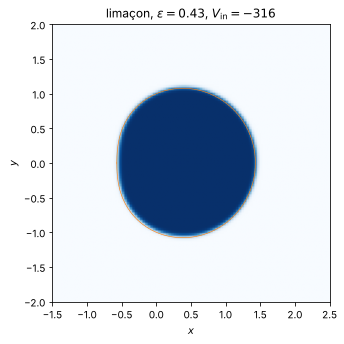

In [3]:
R, eps, n = 1.0, 0.43, 3.3
k = 8.0
E0 = k**2 / 2
cavity = so.LimaconPotential2d.dielectric(R, eps, n, E0, w=0.03)
V_in = (1 - n**2) * E0

size = ((-5.6, 6.4), (-6.0, 6.0))
N = 320
absorber = so.BoundaryAbsorber2d(size, width=2.0, strength=20.0)


def make_grid(psi0):
    return so.Grid2d(size, N, cavity, psi0, absorber=absorber, dtype=np.complex64)


grid = make_grid(so.Gaussian2d(0.0, 0.0, 1.0))
phi = np.linspace(-np.pi, np.pi, 400)
xb, yb = cavity.boundary(phi)


def draw_boundary(ax, color="white"):
    ax.plot(xb, yb, c=color, lw=0.6)


fig, ax = plt.subplots(figsize=(5, 5))
so.plotting.plot2d(grid, np.real(grid.V), kind="real", ax=ax, cmap="Blues_r")
draw_boundary(ax, "C1")
ax.set(xlim=(-1.5, 2.5), ylim=(-2.0, 2.0))
ax.set_title(f"limaçon, $\\varepsilon = {eps}$, $V_\\mathrm{{in}} = {V_in:.0f}$")
print(f"nkR = {n * k * R:.1f}, wavelength inside {2 * np.pi / (n * k):.2f}, outside {2 * np.pi / k:.2f}")
print(f"grid spacing {grid.dx:.4f}")

## Exciting the cavity

Two Gaussian wavepackets start just inside the rim at the top and the bottom and run along it in opposite
directions, with the momentum $nk$ of a wave inside. Their sum is symmetric under $y \to -y$, like the
limaçon, so only the even modes are excited; they are standing waves. Most of the packets escapes at
once, but the part that matches a whispering gallery mode stays for a long time. Outside the cavity, an
absorbing layer at the edges of the grid swallows the emitted waves.

Since the well is deep, the kinetic energy inside is large and the time step needs to be small. The split
operator method of order 4 would allow larger steps, but its negative substeps amplify the waves in the
absorber, so we stay with order 2.

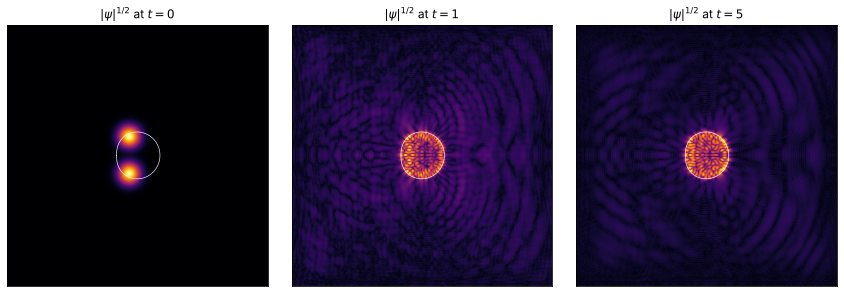

In [4]:
p = n * k
psi0 = so.Gaussian2d(0.0, 0.85, 0.25, px=-p) + so.Gaussian2d(0.0, -0.85, 0.25, px=-p)
grid = make_grid(psi0)
grid.renormalize_psi()
prop = so.SplitOperator()
dt, t_max = 0.002, 40.0

corr = so.analyzers.AutoCorrelation()
corr(grid)
snapshots = {0.0: grid.psi.copy()}
for t in [1.0, 5.0]:
    prop.propagate(grid, dt, round((t - grid.t) / dt), callback=corr, every=5)
    snapshots[t] = grid.psi.copy()
prop.propagate(grid, dt, round((t_max - grid.t) / dt), callback=corr, every=5)

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, (t, psi) in zip(axs, snapshots.items()):
    so.plotting.plot2d(grid, np.abs(psi) ** 0.5, kind="real", ax=ax, cmap="inferno")
    draw_boundary(ax)
    ax.set(title=f"$|\\psi|^{{1/2}}$ at $t = {t:.0f}$", xlabel="", ylabel="", xticks=[], yticks=[])
plt.tight_layout()

## Spectrum

The Fourier transform of the autocorrelation function $C(t) = \langle\psi_0|\psi(t)\rangle$ shows the
resonances as peaks. A resonance that decays at the rate $\Gamma$ (of the probability) has the width $\Gamma$;
the quality factor is $Q = E/\Gamma$. The window limits the resolution to about $2\pi/t_\mathrm{max}$.
For each peak we also print the refractive index it sees, $n' = \sqrt{(E - V_\mathrm{in})/E}$.

E =  33.61   n' = 3.23
E =  19.32   n' = 4.17
E =  36.59   n' = 3.11
E =  46.80   n' = 2.79


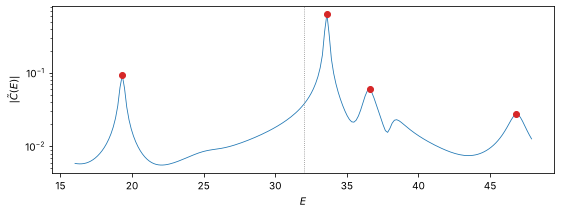

In [5]:
E, spectrum = corr.spectrum()
sel = (E > 0.5 * E0) & (E < 1.5 * E0)
peaks, _ = find_peaks(np.where(sel, spectrum, 0.0), height=0.02 * spectrum[sel].max())
energies = E[peaks[np.argsort(spectrum[peaks])[::-1][:4]]]

fig, ax = plt.subplots(figsize=(9, 3))
ax.semilogy(E[sel], spectrum[sel], lw=0.8)
ax.plot(energies, np.interp(energies, E, spectrum), "o", c="C3")
ax.axvline(E0, c="gray", ls=":", lw=0.8)
ax.set(xlabel="$E$", ylabel=r"$|\tilde C(E)|$")
for e in energies:
    print(f"E = {e:6.2f}   n' = {np.sqrt((e - V_in) / e):.2f}")

## Modes

Energy filtering with `EigenstateFilter` turns the peaks into the modes.

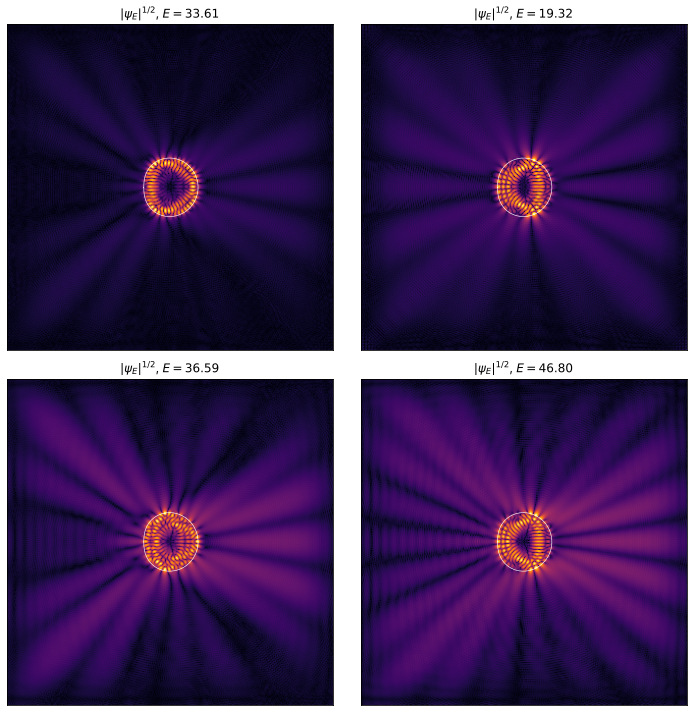

In [6]:
grid = make_grid(psi0)
grid.renormalize_psi()
filt = so.analyzers.EigenstateFilter(energies, t_max)
filt(grid)
prop.propagate(grid, dt, round(t_max / dt), callback=filt, every=2)
modes = filt.eigenstates()

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for ax, mode, e in zip(axs.flat, modes, energies):
    so.plotting.plot2d(grid, np.abs(mode) ** 0.5, kind="real", ax=ax, cmap="inferno")
    draw_boundary(ax)
    ax.set(title=f"$|\\psi_E|^{{1/2}}$, $E = {e:.2f}$", xlabel="", ylabel="", xticks=[], yticks=[])
plt.tight_layout()

The mode at $E \approx E_0$ is a whispering gallery mode: it runs along the rim, and its emission leaves in
beams. The mode near $E = 19$ sees a much larger index $n'$, so it belongs to a different cavity, optically
speaking.

## Lifetimes and far fields

Now we start from each mode alone and watch it decay. The norm gives the decay rate $\Gamma$ and so $Q$.

For the far field, note that a wave far from its source moves along its momentum. The analyzer `FarField`
takes the wave in a ring around the cavity, here $2 < r < 3.8$, which leaves out the cavity and its
evanescent fields. It Fourier transforms that wave and integrates the momentum density over time, then
over $|\mathbf{k}|$, which gives the intensity per direction $\varphi$. The time integral counts every
part of the emitted wave, whenever it leaves. Simply recording the density on a ring of this size would
still give a near field: its lobes shift with the radius of the ring.

The modes are not perfectly clean, since the filter has a finite resolution. We skip the first time units,
in which the admixtures leave the cavity, and measure afterwards.

In [7]:
center = (0.4, 0.0)  # middle of the limaçon along x
t_skip, t_measure = 3.0, 20.0
results = []
for mode, e in zip(modes, energies):
    grid = make_grid(psi0)
    grid.psi = mode.copy()  # the grid would otherwise use the array itself
    prop.propagate(grid, dt, round(t_skip / dt))
    k_mode = np.sqrt(2 * e)
    obs = so.analyzers.Observables()
    far = so.analyzers.FarField(2.0, 3.8, center=center, k_range=(0.5 * k_mode, 1.5 * k_mode))
    obs(grid)
    far(grid)
    prop.propagate(grid, dt, round(t_measure / dt), callback=[obs, far], every=5)
    gamma = -np.polyfit(obs.t, np.log(obs.norm**2), 1)[0]
    results.append((e, e / gamma, far))
    print(f"E = {e:6.2f}   Gamma = {gamma:.3f}   Q = {e / gamma:4.0f}")

E =  33.61   Gamma = 0.089   Q =  378


E =  19.32   Gamma = 0.193   Q =  100


E =  36.59   Gamma = 0.128   Q =  286


E =  46.80   Gamma = 0.135   Q =  346


As a check, the far field of a stationary mode also follows from its values on a circle of radius $r_0$
outside the cavity. There it is a sum of outgoing waves, $\psi_E(r_0, \varphi) = \sum_m a_m
H^{(1)}_m(k r_0)\,e^{im\varphi}$, and the Hankel functions become $H^{(1)}_m(kr) \approx
\sqrt{2/\pi kr}\,e^{i(kr - m\pi/2 - \pi/4)}$ for large $r$, so the far field is
$|\sum_m a_m (-i)^m e^{im\varphi}|^2$.

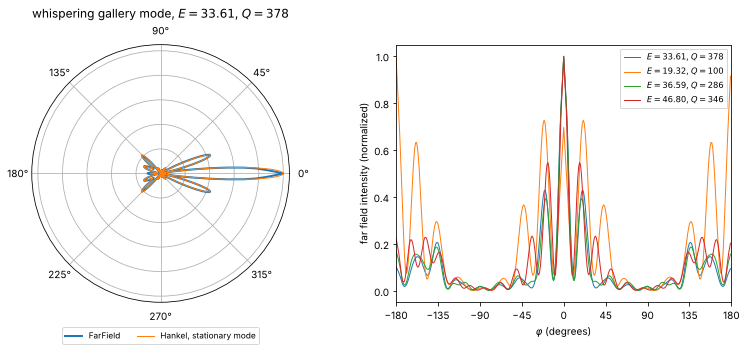

In [8]:
def hankel_far_field(psi_E, E, r0, n_phi=720, m_max=60):
    phi = 2 * np.pi * np.arange(n_phi) / n_phi
    interp = RegularGridInterpolator((grid.x_vals, grid.y_vals), psi_E)
    values = interp(np.stack([center[0] + r0 * np.cos(phi), center[1] + r0 * np.sin(phi)], axis=-1))
    m = np.arange(-m_max, m_max + 1)
    a = np.exp(-1j * np.outer(m, phi)) @ values / n_phi / hankel1(m, np.sqrt(2 * E) * r0)
    far = np.abs(np.exp(1j * np.outer(phi, m)) @ (a * (-1j) ** m)) ** 2
    return np.where(phi < np.pi, phi, phi - 2 * np.pi), far


e, Q, far = results[0]
fig = plt.figure(figsize=(11, 5))
ax = fig.add_subplot(1, 2, 1, projection="polar")
ax.plot(far.angles, far.intensity / far.intensity.max(), lw=2, label="FarField")
phi_h, far_h = hankel_far_field(modes[0], e, r0=3.0)
ax.plot(phi_h, far_h / far_h.max(), lw=1, label="Hankel, stationary mode")
ax.set(title=f"whispering gallery mode, $E = {e:.2f}$, $Q = {Q:.0f}$", yticklabels=[])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncols=2, fontsize="small")

ax = fig.add_subplot(1, 2, 2)
for e, Q, far in results:
    ax.plot(np.degrees(far.angles), far.intensity / far.intensity.max(), lw=1, label=f"$E = {e:.2f}$, $Q = {Q:.0f}$")
ax.set(xlabel=r"$\varphi$ (degrees)", ylabel="far field intensity (normalized)", xlim=(-180, 180))
ax.set_xticks(range(-180, 181, 45))
ax.legend(fontsize="small")
plt.tight_layout()

The time-dependent measurement and the Hankel extrapolation agree. The emission is directional: most of it
leaves in a narrow beam around $\varphi = 0$, the side opposite to the dimple, with side lobes near
$\pm 20°$ and weaker ones around $\pm 135°$. The lobes are the interference of light leaving the rim at
different points.

The modes near $E_0$ have similar far fields, although they look different inside the cavity. This is a
ray effect: in the limaçon, rays leave the cavity along the *unstable manifolds* of a few periodic orbits,
which fix the escape directions for all modes alike (Wiersig and Hentschel 2008; Shinohara et al.,
Phys. Rev. A **80**, 031801 (2009) compare rays and waves in detail). The mode with the much larger index
$n'$ emits differently.

The quality factors here are a few hundred. They grow quickly with the size: at $nkR \approx 26$ the
wavelength is still a quarter of the radius, while the experiments, at $nkR$ of several hundred, reach
$Q \sim 10^5$. Things to try: a circle (`eps=0`), which emits into all directions alike; other
deformations and refractive indices; a larger $k$ on a finer grid.